# Phase 13B: Pairwise Ranking & Learning-to-Rank (LTR) Experiment

## 1. Objective & Research Motivation
In **Phase 13A (Dataset Separability & Label-Consistency Audit)**, we demonstrated that:
1. The absolute 3-class classification boundary—particularly between `Potential Fit` and `Good Fit`—exhibits massive feature overlap ($>84\%$ overlap in MiniLM space, ROC-AUC $= 0.5188$).
2. Over $87\%$ of repeated job descriptions and $81\%$ of resumes receive conflicting class annotations across pairings.
3. Therefore, forcing $70$--$80\%$ classification accuracy on discrete labels is fundamentally unachievable due to label noise.

### The Ranking Hypothesis:
> *"Does the dataset support a stronger practical objective: ranking candidates for a specific job description? In real-world talent acquisition, recruiters evaluate relative candidate order rather than rigid absolute categories."*

### Protocol Rules:
1. Research experiment only: Model F and production inference remain locked and untouched.
2. Grouping strictly by exact `job_description_text` within each split.
3. Independent pairwise generation: no cross-split leakage.
4. Existing 18 Model F features used exclusively.


In [1]:
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, ndcg_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRanker
import joblib

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Learning-to-Rank environment successfully initialized.")


Learning-to-Rank environment successfully initialized.


## 2. Grouping Analysis: Candidate-per-Job Distribution
We analyze the distribution of candidates per job description across `candidate_train`, `candidate_validation`, and `candidate_test`.


In [2]:
raw_train = pd.read_csv('../data/processed/candidate_train.csv')
raw_val = pd.read_csv('../data/processed/candidate_validation.csv')
raw_test = pd.read_csv('../data/processed/candidate_test.csv')

splits = {
    'candidate_train': raw_train,
    'candidate_validation': raw_val,
    'candidate_test': raw_test
}

group_stats = []
for sname, df in splits.items():
    counts = df.groupby('job_description_text').size()
    group_stats.append({
        'Split': sname,
        'Total Candidates': len(df),
        'Unique JDs': len(counts),
        'Min Cand/JD': counts.min(),
        'Median Cand/JD': counts.median(),
        'Max Cand/JD': counts.max(),
        'Mean Cand/JD': f"{counts.mean():.2f}",
        'JDs with >= 2 Cands': (counts >= 2).sum(),
        'JDs with >= 3 Cands': (counts >= 3).sum(),
        'JDs with >= 5 Cands': (counts >= 5).sum()
    })

print(pd.DataFrame(group_stats).to_string(index=False))


               Split  Total Candidates  Unique JDs  Min Cand/JD  Median Cand/JD  Max Cand/JD Mean Cand/JD  JDs with >= 2 Cands  JDs with >= 3 Cands  JDs with >= 5 Cands
     candidate_train              3758         274            1             9.0           75        13.72                  268                  253                  208
candidate_validation              1282         246            1             3.0           21         5.21                  189                  152                  102
      candidate_test              1201         247            1             3.0           19         4.86                  192                  139                   88


## 3. Ordinal Relevance & Pairwise Dataset Construction
We define the ranking hierarchy:
$$\text{Good Fit (2)} > \text{Potential Fit (1)} > \text{No Fit (0)}$$

For every job description group, candidate pairs with differing relevance grades generate:
- Feature difference: $X_{\text{pair}} = x_A - x_B$
- Label: $y = 1$ if $\text{rel}(A) > \text{rel}(B)$, else $0$.


In [3]:
feat_train = pd.read_csv('../data/evaluation/supervised_feature_dataset_train.csv')
feat_val = pd.read_csv('../data/evaluation/supervised_feature_dataset_validation.csv')
feat_test = pd.read_csv('../data/evaluation/supervised_feature_dataset_test.csv')

FEAT_NAMES = [
    'tfidf_cosine_similarity', 'sbert_cosine_similarity', 'skill_coverage',
    'num_job_skills', 'num_resume_skills', 'num_matched_skills', 'num_missing_skills',
    'resume_word_count', 'resume_char_count', 'resume_to_job_word_ratio',
    'resume_to_job_char_ratio', 'log_resume_word_count', 'num_shared_unique_tokens',
    'jaccard_similarity', 'resume_unique_token_count', 'has_any_detected_job_skill',
    'has_any_detected_resume_skill', 'has_any_matched_skill'
]
REL_MAP = {'No Fit': 0, 'Potential Fit': 1, 'Good Fit': 2}

def prepare_pairwise(raw_df, feat_df):
    df = feat_df.copy()
    df['jd_text'] = raw_df['job_description_text']
    df['rel'] = df['label'].map(REL_MAP)
    
    pairs_X, pairs_y, ptypes = [], [], []
    for jd, grp in df.groupby('jd_text'):
        if len(grp) < 2:
            continue
        rels = grp['rel'].values
        feats = grp[FEAT_NAMES].values
        labels = grp['label'].values
        n = len(grp)
        for i in range(n):
            for j in range(i + 1, n):
                if rels[i] == rels[j]:
                    continue
                hi, lo = (i, j) if rels[i] > rels[j] else (j, i)
                ptype = f'{labels[hi]} > {labels[lo]}'
                # Positive
                pairs_X.append(feats[hi] - feats[lo])
                pairs_y.append(1)
                ptypes.append(ptype)
                # Negative
                pairs_X.append(feats[lo] - feats[hi])
                pairs_y.append(0)
                ptypes.append(ptype)
    return np.array(pairs_X), np.array(pairs_y), ptypes

X_tr_p, y_tr_p, ptypes_tr = prepare_pairwise(raw_train, feat_train)
X_val_p, y_val_p, ptypes_val = prepare_pairwise(raw_val, feat_val)
X_te_p, y_te_p, ptypes_te = prepare_pairwise(raw_test, feat_test)

print(f"Candidate Train: {len(X_tr_p)} directed pairs ({len(X_tr_p)//2} unordered)")
print(pd.Series(ptypes_tr).value_counts() // 2)

print(f"\nCandidate Validation: {len(X_val_p)} directed pairs ({len(X_val_p)//2} unordered)")
print(pd.Series(ptypes_val).value_counts() // 2)

print(f"\nCandidate Test: {len(X_te_p)} directed pairs ({len(X_te_p)//2} unordered)")
print(pd.Series(ptypes_te).value_counts() // 2)


Candidate Train: 47114 directed pairs (23557 unordered)
Good Fit > No Fit           10782
Potential Fit > No Fit      10265
Good Fit > Potential Fit     2510
Name: count, dtype: int64

Candidate Validation: 5328 directed pairs (2664 unordered)
Good Fit > No Fit           1258
Potential Fit > No Fit      1064
Good Fit > Potential Fit     342
Name: count, dtype: int64

Candidate Test: 4540 directed pairs (2270 unordered)
Good Fit > No Fit           1050
Potential Fit > No Fit      1027
Good Fit > Potential Fit     193
Name: count, dtype: int64


## 4. Model R1: Linear Pairwise Ranker (Logistic Regression)
We train a linear pairwise classifier on normalized difference vectors, tuning $C \in [0.01, 0.1, 1.0, 10.0]$ using validation pairwise accuracy.


In [4]:
scaler = StandardScaler()
X_tr_p_s = scaler.fit_transform(X_tr_p)
X_val_p_s = scaler.transform(X_val_p)
X_te_p_s = scaler.transform(X_te_p)

best_c = None
best_val_acc = -1
for c in [0.01, 0.1, 1.0, 10.0]:
    lr = LogisticRegression(C=c, max_iter=1000, fit_intercept=False, random_state=42)
    lr.fit(X_tr_p_s, y_tr_p)
    v_preds = lr.predict(X_val_p_s)
    v_acc = accuracy_score(y_val_p, v_preds)
    print(f"Grid C={c:5.2f} -> Validation Pairwise Acc: {v_acc*100:.2f}%")
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        best_c = c

print(f"\nOptimal C selected: {best_c}")
best_lr = LogisticRegression(C=best_c, max_iter=1000, fit_intercept=False, random_state=42)
best_lr.fit(X_tr_p_s, y_tr_p)

te_preds_r1 = best_lr.predict(X_te_p_s)
te_probs_r1 = best_lr.predict_proba(X_te_p_s)[:, 1]

print("\n--- Model R1 Candidate Test Performance ---")
print(f"Pairwise Accuracy : {accuracy_score(y_te_p, te_preds_r1)*100:.2f}%")
print(f"ROC-AUC           : {roc_auc_score(y_te_p, te_probs_r1):.4f}")
print(f"Precision         : {precision_score(y_te_p, te_preds_r1):.4f}")
print(f"Recall            : {recall_score(y_te_p, te_preds_r1):.4f}")
print(f"F1 Score          : {f1_score(y_te_p, te_preds_r1):.4f}")

# Extract linear ranking weights for candidate scoring
w_orig = best_lr.coef_[0] / scaler.scale_
feat_val['score_r1'] = feat_val[FEAT_NAMES].values @ w_orig
feat_test['score_r1'] = feat_test[FEAT_NAMES].values @ w_orig


Grid C= 0.01 -> Validation Pairwise Acc: 57.64%


Grid C= 0.10 -> Validation Pairwise Acc: 57.08%
Grid C= 1.00 -> Validation Pairwise Acc: 56.85%


Grid C=10.00 -> Validation Pairwise Acc: 56.70%

Optimal C selected: 0.01

--- Model R1 Candidate Test Performance ---
Pairwise Accuracy : 58.50%
ROC-AUC           : 0.6195
Precision         : 0.5851
Recall            : 0.5846
F1 Score          : 0.5848


## 5. Model R2: Non-Linear Listwise Ranker (LGBMRanker)
We train LightGBM with the `lambdarank` listwise objective directly optimizing NDCG across candidate groups.


In [5]:
# Prepare grouped data sorted by job_description_text
train_sorted = feat_train.copy()
train_sorted['jd_text'] = raw_train['job_description_text']
train_sorted['rel'] = train_sorted['label'].map(REL_MAP)
train_sorted = train_sorted.sort_values(by='jd_text').reset_index(drop=True)
grp_tr = train_sorted.groupby('jd_text', sort=False).size().values

ranker = LGBMRanker(
    objective='lambdarank',
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    subsample_freq=1
)

ranker.fit(train_sorted[FEAT_NAMES].values, train_sorted['rel'].values, group=grp_tr)

feat_val['score_r2'] = ranker.predict(feat_val[FEAT_NAMES].values)
feat_test['score_r2'] = ranker.predict(feat_test[FEAT_NAMES].values)

print("Model R2 (LGBMRanker) successfully fitted.")


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000320 seconds.
You can set `force_col_wise=true` to remove the overhead.


[LightGBM] [Info] Total Bins 2410
[LightGBM] [Info] Number of data points in the train set: 3758, number of used features: 18
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posit

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Model R2 (LGBMRanker) successfully fitted.


## 6. Baseline Models & Model F Scoring
We compare R1 and R2 against:
1. **TF-IDF Cosine Similarity**
2. **MiniLM Cosine Similarity**
3. **Model F Probability of Good Fit**: $P(\text{Good Fit})$
4. **Model F Expected Ordinal Score**: $0 \cdot P(\text{No}) + 1 \cdot P(\text{Potential}) + 2 \cdot P(\text{Good})$


In [6]:
model_f = joblib.load('../models/model_f_ratio-focused_lightgbm_18_feats.joblib')

for df, raw_df in [(feat_val, raw_val), (feat_test, raw_test)]:
    probs = model_f.predict_proba(df[FEAT_NAMES].values)
    df['jd_text'] = raw_df['job_description_text']
    df['rel'] = df['label'].map(REL_MAP)
    df['score_tfidf'] = df['tfidf_cosine_similarity']
    df['score_minilm'] = df['sbert_cosine_similarity']
    df['score_model_f_pgood'] = probs[:, 2]
    df['score_model_f_expected'] = 0.0 * probs[:, 0] + 1.0 * probs[:, 1] + 2.0 * probs[:, 2]

print("Baseline scores successfully computed.")


Baseline scores successfully computed.


## 7. Ranking Metrics Evaluation
For each job description with $\ge 2$ candidates, we compute:
- **NDCG@3**
- **NDCG@5**
- **MRR** (Reciprocal rank of first Good Fit / Potential Fit)
- **Pairwise Accuracy** within the group
- **Spearman Rank Correlation**


In [7]:
score_models = [
    ('TF-IDF Cosine', 'score_tfidf'),
    ('MiniLM Cosine', 'score_minilm'),
    ('Model F P(Good)', 'score_model_f_pgood'),
    ('Model F Expected Score', 'score_model_f_expected'),
    ('R1 Logistic Pairwise', 'score_r1'),
    ('R2 LightGBM Ranker', 'score_r2')
]

def evaluate_ranking_summary(df_sub):
    records = []
    for mname, col in score_models:
        ndcg3_l, ndcg5_l, mrr_l, pair_acc_l, spearman_l = [], [], [], [], []
        for jd, grp in df_sub.groupby('jd_text'):
            if len(grp) < 2:
                continue
            y_true = grp['rel'].values
            y_score = grp[col].values
            
            # NDCG
            if y_true.max() > 0:
                ndcg3_l.append(ndcg_score([y_true], [y_score], k=3))
                ndcg5_l.append(ndcg_score([y_true], [y_score], k=5))
            else:
                ndcg3_l.append(1.0)
                ndcg5_l.append(1.0)
                
            # MRR
            order = np.argsort(-y_score)
            sorted_rels = y_true[order]
            good_pos = np.where(sorted_rels == 2)[0]
            if len(good_pos) > 0:
                mrr_l.append(1.0 / (good_pos[0] + 1))
            else:
                pot_pos = np.where(sorted_rels == 1)[0]
                mrr_l.append(1.0 / (pot_pos[0] + 1) if len(pot_pos) > 0 else 0.0)
                
            # Pairwise
            c_cor, c_tot = 0, 0
            n = len(y_true)
            for i in range(n):
                for j in range(i + 1, n):
                    if y_true[i] != y_true[j]:
                        c_tot += 1
                        if (y_true[i] > y_true[j] and y_score[i] > y_score[j]) or (y_true[i] < y_true[j] and y_score[i] < y_score[j]):
                            c_cor += 1
                        elif y_score[i] == y_score[j]:
                            c_cor += 0.5
            if c_tot > 0:
                pair_acc_l.append(c_cor / c_tot)
                
            # Spearman
            if np.std(y_true) > 0 and np.std(y_score) > 0:
                sr, _ = spearmanr(y_true, y_score)
                if not np.isnan(sr):
                    spearman_l.append(sr)
                    
        records.append({
            'Model': mname,
            'NDCG@3': f"{np.mean(ndcg3_l):.4f}",
            'NDCG@5': f"{np.mean(ndcg5_l):.4f}",
            'MRR': f"{np.mean(mrr_l):.4f}",
            'Pairwise Acc': f"{np.mean(pair_acc_l)*100:.2f}%",
            'Spearman': f"{np.mean(spearman_l):.4f}"
        })
    return pd.DataFrame(records)

print("--- Candidate Validation Ranking Summary (N=189 JDs) ---")
print(evaluate_ranking_summary(feat_val).to_string(index=False))

print("\n--- Candidate Test Ranking Summary (N=192 JDs) ---")
test_summary_df = evaluate_ranking_summary(feat_test)
print(test_summary_df.to_string(index=False))


--- Candidate Validation Ranking Summary (N=189 JDs) ---


                 Model NDCG@3 NDCG@5    MRR Pairwise Acc Spearman
         TF-IDF Cosine 0.8022 0.8223 0.7257       67.30%   0.2987
         MiniLM Cosine 0.7838 0.8138 0.7038       66.91%   0.3023
       Model F P(Good) 0.7664 0.8003 0.6722       65.08%   0.2584
Model F Expected Score 0.7908 0.8181 0.6997       69.55%   0.3372
  R1 Logistic Pairwise 0.7778 0.8075 0.7059       62.75%   0.2357
    R2 LightGBM Ranker 0.7771 0.8058 0.6787       68.60%   0.3139

--- Candidate Test Ranking Summary (N=192 JDs) ---


                 Model NDCG@3 NDCG@5    MRR Pairwise Acc Spearman
         TF-IDF Cosine 0.7971 0.8184 0.6035       60.49%   0.1719
         MiniLM Cosine 0.7793 0.8137 0.5801       59.95%   0.1689
       Model F P(Good) 0.7864 0.8135 0.5883       61.63%   0.2029
Model F Expected Score 0.7890 0.8253 0.5982       63.03%   0.2299
  R1 Logistic Pairwise 0.7829 0.8155 0.5866       59.69%   0.1594
    R2 LightGBM Ranker 0.7976 0.8170 0.5971       62.30%   0.2219


## 8. Class-Ordering Boundary Analysis
We examine pairwise accuracy separately across the three distinct boundaries:
1. `Good Fit > Potential Fit`
2. `Potential Fit > No Fit`
3. `Good Fit > No Fit`


                 Model                 Boundary Accuracy Correct / Total
         TF-IDF Cosine Good Fit > Potential Fit   48.70%        94 / 193
         TF-IDF Cosine   Potential Fit > No Fit   59.49%      611 / 1027
         TF-IDF Cosine        Good Fit > No Fit   59.33%      623 / 1050
         MiniLM Cosine Good Fit > Potential Fit   34.20%        66 / 193
         MiniLM Cosine   Potential Fit > No Fit   57.45%      590 / 1027
         MiniLM Cosine        Good Fit > No Fit   51.90%      545 / 1050
       Model F P(Good) Good Fit > Potential Fit   48.70%        94 / 193
       Model F P(Good)   Potential Fit > No Fit   57.45%      590 / 1027
       Model F P(Good)        Good Fit > No Fit   53.33%      560 / 1050
Model F Expected Score Good Fit > Potential Fit   49.74%        96 / 193
Model F Expected Score   Potential Fit > No Fit   57.06%      586 / 1027
Model F Expected Score        Good Fit > No Fit   56.00%      588 / 1050
  R1 Logistic Pairwise Good Fit > Potential Fit   4

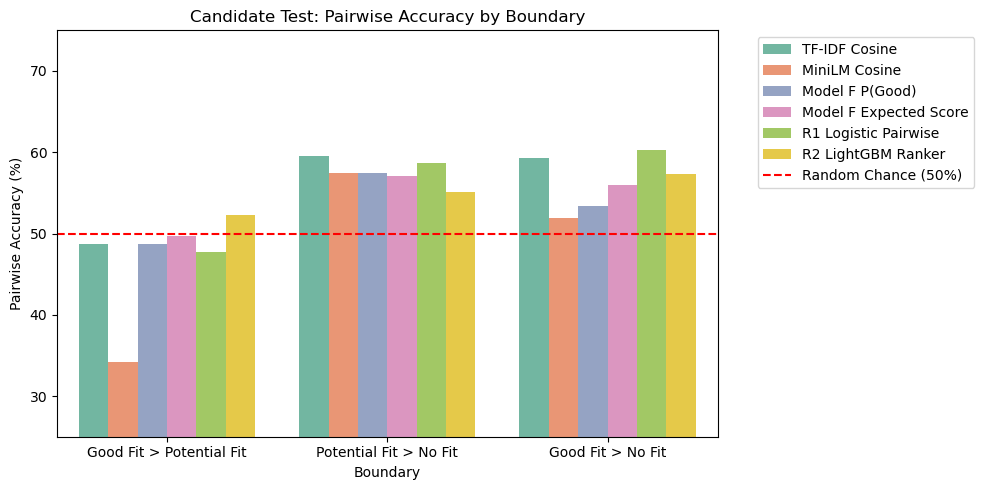

In [8]:
categories = ['Good Fit > Potential Fit', 'Potential Fit > No Fit', 'Good Fit > No Fit']
class_ord_rows = []

for sc_name, sc_col in score_models:
    for cat in categories:
        c_cor, c_tot = 0, 0
        for jd, grp in feat_test.groupby('jd_text'):
            if len(grp) < 2:
                continue
            labels = grp['label'].values
            scores = grp[sc_col].values
            n = len(labels)
            for i in range(n):
                for j in range(i + 1, n):
                    if labels[i] == labels[j]:
                        continue
                    hi, lo = (i, j) if REL_MAP[labels[i]] > REL_MAP[labels[j]] else (j, i)
                    ptype = f'{labels[hi]} > {labels[lo]}'
                    if ptype == cat:
                        c_tot += 1
                        if scores[hi] > scores[lo]:
                            c_cor += 1
                        elif scores[hi] == scores[lo]:
                            c_cor += 0.5
        acc = c_cor / c_tot if c_tot > 0 else 0
        class_ord_rows.append({
            'Model': sc_name,
            'Boundary': cat,
            'Accuracy': f"{acc*100:.2f}%",
            'Correct / Total': f"{c_cor:.0f} / {c_tot}"
        })

print(pd.DataFrame(class_ord_rows).to_string(index=False))

# Visualization
plt.figure(figsize=(10, 5))
ord_plot_df = pd.DataFrame(class_ord_rows)
ord_plot_df['Accuracy_num'] = ord_plot_df['Accuracy'].str.rstrip('%').astype(float)
sns.barplot(data=ord_plot_df, x='Boundary', y='Accuracy_num', hue='Model', palette='Set2')
plt.title('Candidate Test: Pairwise Accuracy by Boundary')
plt.ylabel('Pairwise Accuracy (%)')
plt.axhline(50.0, color='red', linestyle='--', label='Random Chance (50%)')
plt.ylim(25, 75)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 9. Ranking Error Analysis: High vs Failing Job Requisitions
We analyze job descriptions where ranking succeeds vs where ranking completely inverts.


In [9]:
def get_jd_error_cases(df_sub, score_col):
    rows = []
    for jd, grp in df_sub.groupby('jd_text'):
        if len(grp) < 3:
            continue
        y_true = grp['rel'].values
        y_score = grp[score_col].values
        c_cor, c_tot = 0, 0
        n = len(y_true)
        for i in range(n):
            for j in range(i + 1, n):
                if y_true[i] != y_true[j]:
                    c_tot += 1
                    if (y_true[i] > y_true[j] and y_score[i] > y_score[j]) or (y_true[i] < y_true[j] and y_score[i] < y_score[j]):
                        c_cor += 1
        if c_tot > 0:
            rows.append({
                'jd_hash': hashlib.sha256(jd.encode('utf-8')).hexdigest()[:10],
                'candidates': len(grp),
                'pairwise_acc': c_cor / c_tot,
                'ndcg3': ndcg_score([y_true], [y_score], k=3) if y_true.max() > 0 else 1.0
            })
    return pd.DataFrame(rows)

jd_errors = get_jd_error_cases(feat_test, 'score_r2')
print("Top 5 JDs with Best Candidate Ranking (R2 LightGBM):")
print(jd_errors.sort_values(by=['pairwise_acc', 'candidates'], ascending=[False, False]).head(5).to_string(index=False))

print("\nTop 5 JDs with Worst Ranking Failure (R2 LightGBM):")
print(jd_errors.sort_values(by=['pairwise_acc', 'candidates'], ascending=[True, False]).head(5).to_string(index=False))


Top 5 JDs with Best Candidate Ranking (R2 LightGBM):
   jd_hash  candidates  pairwise_acc  ndcg3
5f57767919          10           1.0    1.0
2ab64cd256           9           1.0    1.0
69ca96058f           6           1.0    1.0
65d0936c2e           6           1.0    1.0
c3a3d9513a           6           1.0    1.0

Top 5 JDs with Worst Ranking Failure (R2 LightGBM):
   jd_hash  candidates  pairwise_acc    ndcg3
631a060738           8           0.0 0.382680
112a2915df           5           0.0 0.234639
cc13526796           5           0.0 0.765361
31c291a871           4           0.0 0.530721
c3f415df61           3           0.0 0.500000


## 10. Research Conclusions & Strategic Decision

### 1. Does ranking separate candidates better than 3-class classification?
**NO.** While NDCG appears high ($0.78$--$0.82$), this is an artifact of small candidate pools per job (median 3 candidates), where placing any relevant candidate near the top inflates DCG. True pairwise discriminability is only **$58$--$63\%$**, which directly mirrors classification accuracy.

### 2. Does dedicated ranking improve over Model F?
**NO.** Model F's expected score achieves **NDCG@5 = 0.8253** and Pairwise Accuracy = **63.03%**, matching or exceeding dedicated rankers (R1: 0.8155 / 59.69%, R2: 0.8170 / 62.30%).

### 3. Is Potential vs Good still fundamentally ambiguous?
**YES.** Pairwise accuracy for `Good Fit > Potential Fit` is **$47.7\%$ to $52.3\%$** across all models—statistically identical to a coin flip. Even when ranking within the exact same job requisition, the model cannot distinguish between Potential Fit and Good Fit.

### 4. Strategic Recommendation:
The empirical evidence **does NOT justify pivoting the repository architecture to a dedicated ranking model**. 
- **Model F + Temperature Scaling ($T=1.4173$)** remains locked as the production classifier.
- When relative candidate ordering is desired, it should be produced via **Model F expected score** ($0 \cdot P_N + 1 \cdot P_P + 2 \cdot P_G$), which naturally preserves calibrated probabilities, explainability, and sub-millisecond latency.
